# Category Propensity Model

WitOmni · Break Through Tech AI Studio, Fall 2026

## What we're doing

We're building a deep learning model that predicts which product categories each customer is likely to buy next quarter. It runs on the UCI Online Retail data for WitOmni: about 500k transactions from roughly 4k customers.

The dataset has no product categories, so we make them ourselves with NLP by grouping about 4k product descriptions into 15–30 categories. The model then reads each customer's purchase history and outputs one probability per category: the chance they buy from it next quarter.

It's trained on all customers, so "will they come back at all" is already baked into every score. The point: "this customer will come back" is nice, but "this customer will probably buy candle holders" tells marketing exactly what to promote to whom.

## What the final product looks like

The output is one scored table with a row for every customer × category pair, and two ways to read it.

| Column | What it means |
| --- | --- |
| Customer ID | Who the score is for |
| Category | One of our NLP-built categories |
| Buy probability | Chance they buy from this category next quarter |
| Expected spend (£) | Buy probability × typical spend in that category, used for ranking |

- **Customer view:** pick a customer and see their category scores, highest first.
- **Campaign view:** pick a category and see customers ranked by expected spend. That's the list of who gets the promo.

The scores don't add up to 100%, since each category is its own yes/no and people buy several. We hand WitOmni the table as a CSV they can load into email or ad tools, plus a Streamlit demo with both views.

## Zero to hero

Already done in September: cleaning, EDA, and customer-level features. Everything below builds on that.

#### Data Cleaning

In [67]:
import os
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import matplotlib

In [68]:
df = pd.read_excel('https://raw.githubusercontent.com/Break-Through-Tech/witOmni-1A-ai-powered-customer-intelligence-for-smarter-marketing/main/data/Online%20Retail.xlsx', header=0)

In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [70]:
df.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386048,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [71]:
df.shape

(541909, 8)

In [72]:
print("Duplicate rows: ", df.duplicated().sum())

Duplicate rows:  5268


In [73]:
df = df.drop_duplicates()

In [74]:
df.shape

(536641, 8)

In [75]:
print(df.isnull().sum())

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64


In [76]:
# removing all the rows w/ missing customerID
df = df.dropna(subset=["CustomerID"])

In [77]:
print(df.isnull().sum())

InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64


In [78]:
# removing cancellation/returned items
df = df[~df["InvoiceNo"].astype(str).str.upper().str.startswith("C")]

In [79]:
# removing invalid transactions (invalid prices or quantities)
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]


In [80]:
# final statistics + check (doing it before dropping non relevant columns)
print(df.dtypes)
print(df.isnull().sum())
print("Duplicate rows: ", df.duplicated().sum())
print("Shape: ", df.shape)
df["CustomerID"] = df["CustomerID"].astype(int)

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID            float64
Country                object
dtype: object
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64
Duplicate rows:  0
Shape:  (392692, 8)


In [81]:
#dropping non relevant columns
df = df.drop(columns=["Country"])

In [82]:
print("Final shape: ", df.shape)
print("\nMissing values: ")
print(df.isnull().sum())
print("\nData types: ")
print(df.dtypes)

Final shape:  (392692, 7)

Missing values: 
InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
dtype: int64

Data types: 
InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
UnitPrice             float64
CustomerID              int64
dtype: object


In [83]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850


In [84]:
import numpy as np
import pandas as pd

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)


### 1. Lock the time split

Pick a cutoff date about 3 months before the data ends. Purchases before it are the history the model sees; categories bought after it are the labels. This keeps the model from peeking at the future.

In [85]:
# set CUTOFF_DATE       There is about 1 year worth of invoices from 12/2010 -> 12/2011
startdate = df["InvoiceDate"].min()
enddate = df["InvoiceDate"].max()
cutoff_date = startdate + (enddate - startdate) * 0.75

# months before and after the cutoff
months_before = (cutoff_date.year - startdate.year) * 12 + (cutoff_date.month - startdate.month)
months_after = (enddate.year - cutoff_date.year) * 12 + (enddate.month - cutoff_date.month) + 1

print(f"Data range:   {startdate.date()} -> {enddate.date()}")
print(f"Cutoff date:  {cutoff_date.date()}")
print()
print(f"Before cutoff: {months_before} months ({startdate.date()} -> {(cutoff_date - pd.Timedelta(days=1)).date()})")
print(f"After cutoff:  {months_after} months ({cutoff_date.date()} -> {enddate.date()})")
print()
print(f"Rows before cutoff: {(df['InvoiceDate'] < cutoff_date).sum():,}")
print(f"Rows after cutoff:  {(df['InvoiceDate'] >= cutoff_date).sum():,}")



Data range:   2010-12-01 -> 2011-12-09
Cutoff date:  2011-09-07

Before cutoff: 9 months (2010-12-01 -> 2011-09-06)
After cutoff:  4 months (2011-09-07 -> 2011-12-09)

Rows before cutoff: 230,209
Rows after cutoff:  162,483


### 2. Build the categories with NLP

- Drop non-products (postage, fees, manual adjustments) and keep one description per StockCode.
- Strip color, pattern, and size words (RED, RETROSPOT, JUMBO) so items group by what they are, not how they look.
- Embed the descriptions with `all-MiniLM-L6-v2` and cluster them with KMeans.
- Have an LLM name each cluster, then merge or split by hand until there are 15–30 categories.
- Spot-check about 20 items per category, then save a `stockcode → category` CSV to the repo.

In [86]:
codes = df["StockCode"].astype(str).str.strip()
is_normal = codes.str.match(r"^\d{5}[A-Za-z]*$")


odd = (df[~is_normal]
       .groupby(codes[~is_normal])
       .agg(Description=("Description", "first"),
            rows=("StockCode", "size"),
            avg_price=("UnitPrice", "mean"))
       .sort_values("rows", ascending=False))
print(odd)


                             Description  rows   avg_price
StockCode                                                 
POST                             POSTAGE  1099   31.570482
M                                 Manual   279  178.406129
C2                              CARRIAGE   133   50.135338
DOT                       DOTCOM POSTAGE    16  744.147500
BANK CHARGES                Bank Charges    12   13.750083
PADS          PADS TO MATCH ALL CUSHIONS     3    0.001000


In [87]:
#filter out non-product StockCodes
df = df[is_normal]

In [88]:
history = df[df["InvoiceDate"] < cutoff_date].copy()
future = df[df["InvoiceDate"] >= cutoff_date].copy()

In [46]:
df.sample(30)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
64661,541658,20767,BLUE PAISLEY JOURNAL,2,2011-01-20 12:16:00,2.55,15529
482845,577485,23306,SET OF 36 PANTRY PAPER DOILIES,7,2011-11-20 11:56:00,1.45,16360
449108,575086,23034,DRAWER KNOB CERAMIC BLACK,24,2011-11-08 13:52:00,1.45,16618
284748,561885,85040A,S/4 PINK FLOWER CANDLES IN BOWL,1,2011-07-31 13:13:00,1.65,15532
413559,572317,23557,LANDMARK FRAME BAKER STREET,1,2011-10-23 16:13:00,12.50,14629
417810,572672,22720,SET OF 3 CAKE TINS PANTRY DESIGN,6,2011-10-25 13:15:00,4.95,13340
342992,566923,85123A,WHITE HANGING HEART T-LIGHT HOLDER,2,2011-09-15 15:05:00,2.95,15511
333331,566193,21218,RED SPOTTY BISCUIT TIN,6,2011-09-09 13:37:00,3.75,14961
407932,571914,22522,CHILDS GARDEN FORK BLUE,12,2011-10-19 15:33:00,0.85,14776
239226,558031,22667,RECIPE BOX RETROSPOT,6,2011-06-24 12:14:00,2.95,14180


In [47]:
# !pip install sentence-transformers

# TODO: keep the most common description per StockCode done
# TODO: strip color / pattern / size words
# TODO: embed descriptions, cluster with KMeans
# TODO: name clusters, finalize 15–30 categories
# TODO: spot-check ~20 items per category
# TODO: save stockcode_to_category.csv

##### Keep most common description per StockCode

In [48]:
#147 out of 3580 stockcodes have more than 1 kind of description
description_counts = history.groupby("StockCode")["Description"].nunique()
print(description_counts.sum(),((description_counts > 1).sum()))

3580 147


In [49]:
#replace variable stock codes with most used description
product_desc = history.groupby("StockCode")["Description"].agg(lambda x: x.value_counts().idxmax())
history["Description"] = history["StockCode"].map(product_desc)

##### Strip color/pattern/size words

In [90]:
#remove colors
colorlist = [c.upper() for c in matplotlib.colors.CSS4_COLORS]
history["cleanedDescription"] = history["Description"].str.replace(r"\b(" + "|".join(colorlist) + r")\b", "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()

In [91]:
history["Description"].str.split().explode().nunique()

2127

In [52]:
%pip install typesafe-sdk

In [53]:
#use Jev to find pattern words
import os
from typesafe_sdk import TypeSafeClient, Noul

words = history["Description"].str.split().explode().dropna().unique().tolist()
pattern_words = []

with TypeSafeClient(api_key=os.getenv("TYPESAFE_API_KEY")) as client:
    for start in range(0, len(words), 20):
        batch = words[start:start + 20]
        questions = {f"w{i}": Noul(instructions=f"Is '{w}' a pattern word (like spotty, stripe, floral)?")
                     for i, w in enumerate(batch)}
        resp = client.system_one(state={"task": "Classify product description words"}, questions=questions)
        pattern_words += [w for i, w in enumerate(batch) if resp.nouls[f"w{i}"].noul > 0.8]

print(pattern_words)


['POLKADOT', 'SPOTTY', 'PAISLEY', 'GINGHAM', 'STRIPEY', 'SWIRLY', 'STRIPES', 'DOTS', 'POLKA', 'CAMOUFLAGE', 'STRIPE', 'SPIRAL', 'SPOTTED', 'FLORAL', 'CAMO', 'POLKADOTS', 'CIRCLES', 'STRIPY', 'PAISELY', 'LATTICE', 'MOSAIC', 'GEOMETRIC', 'PATCHWORK']


In [92]:
pattern_words = ['STARS', 'POLKADOT', 'SPOTTY', 'PAISLEY', 'GINGHAM', 'STRIPEY', 'SWIRLY', 'STRIPES', 'DOTS', 'SPOTS', 'HONEYCOMB', 'POLKA', 'CAMOUFLAGE', 'STRIPE', 'SPIRAL', 'SPOTTED', 'FLORAL', 'CAMO', 'CHECK', 'POLKADOTS', 'STRIPY', 'LATTICE', 'MOSAIC', 'GEOMETRIC', 'PATCHWORK']

In [55]:
#use Jev to find size words

size_words = []
with TypeSafeClient(api_key=os.getenv("TYPESAFE_API_KEY")) as client:
    for start in range(0, len(words), 20):
        batch = words[start:start + 20]
        questions = {f"w{i}": Noul(instructions=f"Is '{w}' a size word (like small, large, mini, jumbo)?")
                     for i, w in enumerate(batch)}
        resp = client.system_one(state={"task": "Classify product description words"}, questions=questions)
        size_words += [w for i, w in enumerate(batch) if resp.nouls[f"w{i}"].noul > 0.8]

print(size_words)


['MINI', 'LARGE', 'JUMBO', 'SMALL', 'GIANT', 'MED', 'LITTLE', 'MEDIUM', 'BIG', 'PETIT', 'COMPACT', 'TINY', 'MINIATURE', 'L', '"L"', 'MID']


In [93]:
size_words = ['MINI', 'LARGE', 'JUMBO', 'SMALL', 'GIANT', 'MED', 'LITTLE', 'MEDIUM', '"M"', 'BIG', 'PETIT', 'COMPACT', 'M', 'TINY', 'MINIATURE', 'L', '"L"']

In [94]:
import re

strip_words = size_words + pattern_words   # add + colorlist to remove colors too
regex = r"\b(" + "|".join(re.escape(w) for w in strip_words) + r")\b"

history["cleanedDescription"] = (history["cleanedDescription"]
                        .str.replace(regex, "", regex=True)
                        .str.replace(r"\s+", " ", regex=True)
                        .str.strip())


In [95]:
history["cleanedDescription"].sample(20)

,cleanedDescription
110625,SET OF 20 KIDS COOKIE CUTTERS
152265,CUPCAKE LACE PAPER SET 6
190542,CARD DOG AND BALL
93663,S/4 FLOWER CANDLES IN BOWL
11915,MEDINA STAMPED METAL BOWL
279351,SPOT CERAMIC DRAWER KNOB
253768,SET/3 ROSE STORAGE BOX
32526,BAG STRAWBERRY
125850,WRAP
200554,DOORMAT KEEP CALM AND COME IN


In [97]:
print(history["cleanedDescription"].nunique())

3111


##### embed descriptions

In [98]:
%pip install sentence-transformers

In [99]:
#create a products table that stores each unique stockcode and its vector embedded description
from sentence_transformers import SentenceTransformer

products = history[["StockCode", "cleanedDescription"]].drop_duplicates("StockCode").reset_index(drop=True)
unique_desc = products["cleanedDescription"].unique().tolist()

model = SentenceTransformer("all-MiniLM-L6-v2")
vectors = model.encode(unique_desc, show_progress_bar=True, normalize_embeddings=True)

desc_to_vec = dict(zip(unique_desc, vectors))
X = np.vstack(products["cleanedDescription"].map(desc_to_vec))
print(X.shape)   # (number of products, 384)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Batches:   0%|          | 0/94 [00:00<?, ?it/s]

(3420, 384)


##### K-Means Clustering

In [100]:
from sklearn.cluster import KMeans


In [64]:
#use elbow method to find best k

ks = range(10, 41)
inertias = [KMeans(n_clusters=k, random_state=42, n_init=10).fit(X).inertia_ for k in ks]

plt.plot(ks, inertias, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

KeyboardInterrupt: 

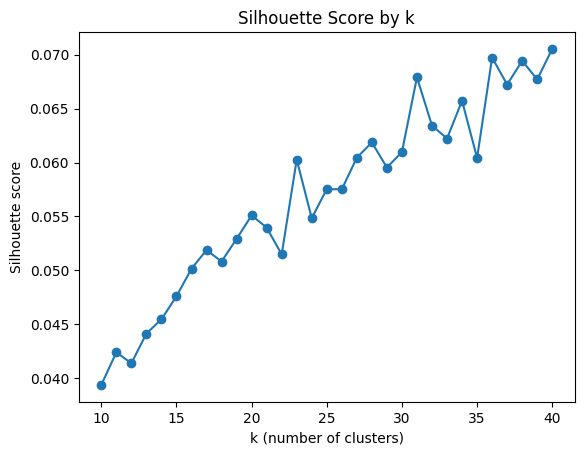

Best k: 40


In [ ]:
from sklearn.metrics import silhouette_score

ks = range(10, 41)
scores = [silhouette_score(X, KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)) for k in ks]

plt.plot(ks, scores, marker="o")
plt.xlabel("k (number of clusters)")
plt.ylabel("Silhouette score")
plt.title("Silhouette Score by k")
plt.show()

print("Best k:", ks[int(np.argmax(scores))])


In [102]:
kmeans = KMeans(n_clusters=23, random_state=42, n_init=10)
products["Cluster"] = kmeans.fit_predict(X)

for c in range(kmeans.n_clusters):
    group = products[products["Cluster"] == c]["cleanedDescription"]
    print(f"\n--- Cluster {c} ({len(group)} products) ---")
    print("\n".join(group))



--- Cluster 0 (282 products) ---
WOOD 2 DRAWER CABINET FINISH
WOOD S/3 CABINET ANT FINISH
STRAWBERRY LUNCH BOX WITH CUTLERY
LUNCH BOX WITH CUTLERY RETROSPOT
SPOT CERAMIC DRAWER KNOB
DRAWER KNOB ACRYLIC EDWARDIAN
CLEAR DRAWER KNOB ACRYLIC EDWARDIAN
WOOD BOARD ANT FINISH
ENAMEL FIRE BUCKET CREAM
ENAMEL BREAD BIN CREAM
FRIDGE MAGNETS US DINER ASSORTED
FRIDGE MAGNETS LES ENFANTS ASSORTED
DINER WALL CLOCK
DINER WALL CLOCK
DINER WALL CLOCK
POPCORN HOLDER
POPCORN HOLDER
RUSTIC SEVENTEEN DRAWER SIDEBOARD
DOUGHNUT TRINKET POT
TV DINNER TRAY VINTAGE
SANDWICH BATH SPONGE
APPLE BATH SPONGE
BREAD BIN DINER STYLE
DRAWER KNOB ACRYLIC EDWARDIAN
DRAWER KNOB ACRYLIC EDWARDIAN
DRAWER KNOB ACRYLIC EDWARDIAN
PLASTERS IN TIN SKULLS
CLEAR ACRYLIC FACETED BANGLE
FULL ENGLISH BREAKFAST PLATE
PLATE
PLATE
PLATE
DRAWERKNOB ACRYLIC EDWARDIAN
CHILDRENS APRON SPACEBOY DESIGN
PLASTERS IN TIN VINTAGE
PLASTERS IN TIN SPACEBOY
KINGS CHOICE BISCUIT TIN
RETROSPOT OVEN GLOVE
RETROSPOT CHILDRENS APRON
COOKING SET RETROSPOT

##### Cluster Names

In [103]:
cluster_names = {
    0: "Kitchenware & Dining",
    1: "Ribbons, Garlands & Hanging Decor",
    2: "Baking",
    3: "Floral & Botanical",
    4: "Kids' Toys & Gifts",
    5: "Boxes, Tins & Storage",
    6: "Garden",
    7: "Glassware & Jars",
    8: "Heart Decorations",
    9: "Lighting & T-Light Holders",
    10: "Bags, Purses & Travel",
    11: "Party & Tableware",
    12: "Signs, Doormats & Doorstops",
    13: "Kids' Toys & Gifts",          # Dolly Girl / Charlie & Lola range
    14: "Stationery & Crafts",
    15: "Jewellery & Accessories",
    16: "Christmas",
    17: "Cushions & Soft Furnishings",
    18: "Mirrors & Photo Frames",
    19: "Jewellery & Accessories",
    20: "Candles & Incense",
    21: "Floral & Botanical",          # rose design range
    22: "Easter & Spring",
}

RULES = [
    ("DROP", r"^(PACKING CHARGE|NEXT DAY CARRIAGE|POSTAGE|DOTCOM POSTAGE|MANUAL|BANK CHARGES|CARRIAGE)$"),
    ("Christmas", r"CHRISTMAS|XMAS|ADVENT|\bNOEL\b|SANTA|REINDEER|SNOWM[AE]N|NATIVITY|YULETIDE|SLEIGH|MISTLETOE|HOLLY|ACRYLIC (HANGING )?JEWEL|WISE MAN"),
    ("Easter & Spring", r"EASTER"),
    ("Lighting & T-Light Holders", r"T-LIGHT (HOLDER|HLDR|SETTING)|TEALIGHT|LANTERN|LAMP ?SHADE|\bLAMP\b|LIGHT (CHAIN|GARLAND)|(?<!T-)\bLIGHTS\b|NIGHT ?LIGHT|(BEDSIDE|TABLE) LIGHT|\bLED\b|LIGHTBULB|STAR BULB|TORCH"),
    ("Candles & Incense", r"CANDLE|T-LIGHTS?\b|INCENSE|OIL BURNER|VOTIVE"),
    ("Jewellery & Accessories", r"NECKLAC|NECKL\b|BRACE?LET|BRACLET|EARRING|BANGLE|BROOCH|CHOKER|PENDANT|LARIAT|(?<!KEY )(?<!NAPKIN )\bRING\b|HAIR ?(CLIP|SLIDE|GRIP|BAND|TIE|COMB)|HAIRCLIP|HAIRSLIDE|HAIRBAND|(PHONE|BAG|BEAD) CHARM|KEY ?RING|KEY[- ]CHAIN|JEWELLERY (STAND|SET)|JEWEL STAND|TIARA"),
    ("Clocks", r"\bCLOCK\b(?! MAGNET)"),
    ("Signs, Doormats & Doorstops", r"DOORMAT|DOORSTOP|\bSIGN\b|DOORSIGN|DOOR HANGER|WOOD(EN)? (BLOCK )?LETTERS|BUILDING BLOCK WORD|NUMBER TILE"),
    ("Hot Water Bottles & Warmers", r"HOT WATER BOTTLE|HAND WARMER|POCKET WARMER|HOTTIE"),
    ("Umbrellas & Rainwear", r"UMBRELLA(?! STAND)|RAIN MAC|PONCHO|RAIN HAT|(EDWARDIAN|DECORATIVE) PARASOL"),
    ("Cushions & Soft Furnishings", r"(?<!PIN )CUSHION|FILLER PAD|\bTHROW\b|QUILT(?!ED)"),
    ("Mirrors & Photo Frames", r"MIRROR|PHOTO ?FRAME|PICTURE FRAME|PHOTO ALBUM|\bFRAME\b|PHOTO (CLIP|CUBE)"),
    ("Cards & Gift Wrap", r"(?<!SNAP )(?<!PLAYING )\bCARDS?\b(?!\s*(HOLDER|WALLET|GAME|KIT))|GREETING|\bWRAP\b|WRAPPING|GIFT TAPE|GIFT TAGS?\b"),
    ("Stationery & Crafts", r"NOTEBOOK|NOTE BOOKS?|JOURNAL|SKETCHBOOK|POCKET BOOK|EXERCISE BOOK|NOTEPAD|ADDRESS BOOK|SCRAP BOOK|PENCIL|\bPENS?\b|ERASER|SHARPENER|STICKERS?\b|STATIONERY|RULER|CRAYON|CHALK|HIGHLIGHTER|TAPE MEASURE|MEASURING TAPE|MEMO ?BOARD|ENVELOPE|PAPERWEIGHT|STAMP SET|STENCIL|WRITING SET|DRAWING SLATE|BOOKCOVER TAPE|BOOK MARK|CANVAS (SET|ART)|PAINT SET|KNITTING|SEWING KIT|CARD KIT|PATCHES"),
    ("Bags, Purses & Travel", r"(?<!IN )(?<!TEA )(?<!PARTY )\bBAGS?\b(?! OF| \d| \+)|PURSE|HANDBAG|WASHBAG|TOTE|SHOPPER|LUGGAGE TAG|CARD WALLET|PASSPORT COVER|BACKPACK|GLASSES CASE"),
    ("Garden", r"PLANTER|PLANT POT|POT HOLDER|WATERING CAN|(HERB|GARDEN) MARKER|GNOME|SECATEURS|KNEELING (PAD|MAT)|GROW (YOUR OWN|A )|SOW 'N' GROW|SEED ENVELOPE|THERMOMETER|GARDEN (TOOLS|SPADE|FORK|TROWEL|RAKE|BRUSH|GLOVES|PARASOL|SET)|CHILDS GARDEN|CHILDRENS GARDEN|HERB GARDEN|PLANT (HOLDER|CAGE|LADDER)|BIRD ?HOUSE|BIRDCAGE"),
    ("Baking", r"CAKE CASES?|BAKING|(COOKIE|BISCUIT) CUTTER|CAKE ?STAND|CAKE TINS?|CAKE (FORK|SLICE|FRILL|COVER)|JELLY MOULD|ROLLING PIN|PASTRY BRUSH|MEASURING SPOONS|CUP ?CAKE|FOUR CASES|LOLLY (MAKERS|MOULDS|HOLDERS)|JAM MAKING"),
    ("Mugs & Teaware", r"\bMUGS?\b|TEACUP|SAUCER|TEAPOT|TEA SET|TEA COSY|(TEA|COFFEE) CADDY|TEA FOR ONE|TEA STRAINER|COFFEE SET|(?<!EGG )(?<!PAPER )\bCUPS?\b"),
    ("Boxes, Tins & Storage", r"STORAGE|TRINKET|MONEY (BOX|BANK)|PIGGY BANK|TISSUE BOX|LUNCH BOX|SEWING BOX|KEEPSAKE BOX|JEWELLERY BOX|JEWEL BOX|NESTING BOXES|STACKING TINS|KNICK KNACK TINS|BISCUITS? TINS?|TREASURE (TIN|BOOK BOX|CHEST)|RECIPE (BOX|BOOK BOX)|SNACK BOXES|FIRST AID|PLASTERS IN TIN|CUTLERY BOX|BUTTON BOX"),
    ("Party & Tableware", r"PARTY|BALLOON|BUNTING|CONFETTI|PAPER (CUPS?|PLATES?|NAPKINS?)|NAPKIN|DOIL(IES|EY|Y)|STRAWS|COCKTAIL|CRACKERS?|PICNIC (HAMPER|BOXES)|PLACEMAT|COASTER|PLACE SETTING|CHOPSTICKS|DISPOSABLE"),
    ("Furniture & Drawer Knobs", r"\b(CABINET|SIDEBOARD|CUPBOARD|STOOL|POUFFE|CHAIR|SHELF|SHELVING|DESK)\b|CHEST (OF|\d|NATURAL)|DRAWER|TRAY TABLE|STEEL .*TABLE|UMBRELLA STAND|LOVE SEAT|HAMMOCK"),
    ("Hooks, Racks & Organisers", r"COAT ?RACK|COATHANGER|\bHOOKS?\b|HANGERS?\b|LETTER (RACK|TRAY|HOLDER)|MAGAZINE RACK|WALL TIDY|ORGANISER|KEY HOLDER|SHOE TIDY"),
    ("Kitchenware & Dining", r"\bBOWLS?\b|\bPLATES?\b|PLATTER|\bTRAYS?\b|(FRYING|MILK|EGG) PAN|BREAD BIN|KITCHEN SCALES|COLANDER|CUTLERY|EGG (CUP|HOLDER)|BUTTER DISH|TOAST ?RACK|APRON|TEA TOWEL|OVEN (GLOVE|MITT)|TABLE ?CLOTH|UTENSIL|SPOON|LADLE|\bJUG\b|FOOD (COVER|CONTAINER)|CONDIMENT|SALT AND PEPPER|SUGAR (DISPENSER|BOWL|TONGS)|SUNDAE DISH|CHEESE DISH|WASHING UP|SCRUBBING BRUSH|APPLE CORER|BISCUIT BARREL|MICROWAVE"),
]
RULES = [(c, re.compile(p, re.I)) for c, p in RULES]

def refine(desc, base):
    for cat, pattern in RULES:
        if pattern.search(desc):
            return cat
    return base

products["Category"] = [refine(d, cluster_names[c]) for d, c in zip(products["cleanedDescription"], products["Cluster"])]
products = products[products["Category"] != "DROP"].reset_index(drop=True)

print(products["Category"].nunique(), "categories")
print(products["Category"].value_counts())

27 categories
Category
Jewellery & Accessories              308
Kitchenware & Dining                 267
Stationery & Crafts                  251
Party & Tableware                    202
Bags, Purses & Travel                195
Candles & Incense                    193
Kids' Toys & Gifts                   181
Christmas                            177
Boxes, Tins & Storage                155
Signs, Doormats & Doorstops          143
Lighting & T-Light Holders           130
Easter & Spring                      126
Cards & Gift Wrap                    103
Mugs & Teaware                       102
Mirrors & Photo Frames               101
Heart Decorations                     98
Garden                                90
Baking                                85
Furniture & Drawer Knobs              78
Floral & Botanical                    77
Ribbons, Garlands & Hanging Decor     75
Glassware & Jars                      65
Cushions & Soft Furnishings           62
Hooks, Racks & Organisers         

### 3. Build the training table

One row per customer: per-category history (how often, how recently, how much spent) plus RFM features. Labels are a yes/no per category for "bought after the cutoff."

##### Label StockCodes with categories

###### History

In [110]:
#give every stock code a category
category_map = dict(zip(products["StockCode"], products["Category"])) #hashmap from stockcode to category

In [111]:
#label each row with a category column
history["Category"] = history["StockCode"].map(category_map)

In [112]:
print(history["Category"].isna().sum())

0


In [113]:
print(history.loc[history["Category"].isna(), "Description"].value_counts())

Series([], Name: count, dtype: int64)


In [114]:
#drop packing and carriage from dataframe because they dont fit a category
history = history.dropna(subset=["Category"])

###### Future

In [115]:
future["Category"] = future["StockCode"].map(category_map)

In [116]:
print(future["Category"].isna().sum())

12024


In [120]:
#12024 items include new products that were not in our history
print(future.loc[future["Category"].isna(), "Description"].value_counts())

Description
VINTAGE DOILY TRAVEL SEWING KIT       358
PLAYING CARDS KEEP CALM & CARRY ON    334
JUMBO BAG PAISLEY PARK                309
LUNCH BAG PAISLEY PARK                305
TRADITIONAL PICK UP STICKS GAME       241
                                     ... 
LETTER "O" BLING KEY RING               1
LETTER "U" BLING KEY RING               1
LETTER "W" BLING KEY RING               1
LETTER "Z" BLING KEY RING               1
PAPER CRAFT , LITTLE BIRDIE             1
Name: count, Length: 283, dtype: int64


In [ ]:
#number of new items in our new item dataframe
new = future.loc[future["Category"].isna()].groupby("StockCode")["Description"].agg(lambda x: x.value_counts().idxmax()).reset_index()
print(len(new))

241


In [125]:
#clean descriptions
new["cleanedDescription"] = new["Description"].str.replace(r"\b(" + "|".join(colorlist) + r")\b", "", regex=True).str.replace(regex, "", regex=True).str.replace(r"\s+", " ", regex=True).str.strip()
new.head(10)

,StockCode,Description,cleanedDescription
0,20678,LARGE BLACK DIAMANTE HAIRSLIDE,DIAMANTE HAIRSLIDE
1,20935,ROUND CACTUS CANDLE,ROUND CACTUS CANDLE
2,22125,UNION JACK HOT WATER BOTTLE,UNION JACK HOT WATER BOTTLE
3,23058,CHRISTMAS HANGING SNOWFLAKE,CHRISTMAS HANGING SNOWFLAKE
4,23074,EMBOSSED HEART TRINKET BOX,EMBOSSED HEART TRINKET BOX
5,23113,PANTRY CHOPPING BOARD,PANTRY CHOPPING BOARD
6,23114,VINTAGE LEAF CHOPPING BOARD,VINTAGE LEAF CHOPPING BOARD
7,23115,RED APPLES CHOPPING BOARD,APPLES CHOPPING BOARD
8,23116,VEGETABLE GARDEN CHOPPING BOARD,VEGETABLE GARDEN CHOPPING BOARD
9,23117,POPPY FIELDS CHOPPING BOARD,POPPY FIELDS CHOPPING BOARD


In [ ]:
#embed the cleaned descriptions and place them in our predefined clusters
new["Cluster"] = kmeans.predict(model.encode(new["cleanedDescription"].tolist(), normalize_embeddings=True))
new["Cluster"].value_counts()

,count
Cluster,
14,26
8,21
22,21
1,20
15,19
4,19
19,15
0,14
11,14


In [131]:
#sort into refined clusters
new["Category"] = [refine(d, cluster_names[c]) for d, c in zip(new["cleanedDescription"], new["Cluster"])]


In [132]:
#add new stockcodes to the hashmap to link them to a category
category_map.update(dict(zip(new["StockCode"], new["Category"])))

In [136]:
#add category labels to the new items in future table 
future["Category"] = future["StockCode"].map(category_map)

In [138]:
#all stockcodes are linked to a category if isna == 0
print(future["Category"].isna().sum())

0


##### RFM per customer

In [143]:
#calculate total spend per column
history["TotalPrice"] = history["Quantity"] * history["UnitPrice"]
history.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,cleanedDescription,Category,TotalPrice
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,HANGING HEART T-LIGHT HOLDER,Lighting & T-Light Holders,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,METAL LANTERN,Lighting & T-Light Holders,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,CREAM CUPID HEARTS COAT HANGER,"Hooks, Racks & Organisers",22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850,KNITTED UNION FLAG HOT WATER BOTTLE,Hot Water Bottles & Warmers,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850,WOOLLY HOTTIE HEART.,Hot Water Bottles & Warmers,20.34


In [152]:
#create RFM columns per customer
customer = history.groupby("CustomerID")
rfm = pd.DataFrame({"Recency": (cutoff_date - customer["InvoiceDate"].max()).dt.days, "Frequency": customer["InvoiceNo"].nunique(), "Monetary": customer["TotalPrice"].sum()})
rfm.head()

,Recency,Frequency,Monetary
CustomerID,,,
12346,231,1,77183.60
12347,35,5,2790.86
12348,154,3,1167.24
12350,216,1,294.40
12352,168,4,641.51


In [156]:
#feature engineering for rfm columns to capture avg order value, unique products bought and customer tenure
rfm["avg_order_value"] = rfm["Monetary"] / rfm["Frequency"]
rfm["unique_products"] = customer["StockCode"].nunique()
rfm["tenure_days"] = (cutoff_date - customer["InvoiceDate"].min()).dt.days
rfm.head()

,Recency,Frequency,Monetary,avg_order_value,unique_products,tenure_days
CustomerID,,,,,,
12346,231,1,77183.60,77183.6000,1,231
12347,35,5,2790.86,558.1720,82,273
12348,154,3,1167.24,389.0800,21,264
12350,216,1,294.40,294.4000,16,216
12352,168,4,641.51,160.3775,24,202


##### Per Category Features

In [165]:
#define category groups per customer
customer_category = history.groupby(["CustomerID", "Category"])

In [166]:
#create dataframe with per category features
per_category = pd.DataFrame({"orders": customer_category["InvoiceNo"].nunique(), "spend": customer_category["TotalPrice"].sum(), "recency": (cutoff_date - customer_category["InvoiceDate"].max()).dt.days})
per_category.head(5)

orders     spend  recency
CustomerID Category                                        
12346      Boxes, Tins & Storage       1  77183.60      231
12347      Bags, Purses & Travel       5    328.00       35
           Baking                      5    340.35       35
           Boxes, Tins & Storage       2     47.85      152
           Candles & Incense           2     51.60       89

In [ ]:
#organize per category data into one row per customer for customer predicions
per_category = per_category.unstack("Category")
per_category.columns = [f"{metric}_{category}" for metric, category in per_category.columns]
per_category.head()

,"orders_Bags, Purses & Travel",orders_Baking,"orders_Boxes, Tins & Storage",orders_Candles & Incense,orders_Cards & Gift Wrap,orders_Christmas,orders_Clocks,orders_Cushions & Soft Furnishings,orders_Easter & Spring,orders_Floral & Botanical,...,recency_Kids' Toys & Gifts,recency_Kitchenware & Dining,recency_Lighting & T-Light Holders,recency_Mirrors & Photo Frames,recency_Mugs & Teaware,recency_Party & Tableware,"recency_Ribbons, Garlands & Hanging Decor","recency_Signs, Doormats & Doorstops",recency_Stationery & Crafts,recency_Umbrellas & Rainwear
CustomerID,,,,,,,,,,,,,,,,,,,,,
12346,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
12347,5.0,5.0,2.0,2.0,NaN,1.0,4.0,NaN,NaN,NaN,...,35.0,35.0,89.0,273.0,89.0,152.0,NaN,273.0,35.0,NaN
12348,NaN,1.0,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,...,NaN,154.0,NaN,NaN,NaN,154.0,NaN,NaN,154.0,NaN
12350,1.0,NaN,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,216.0,216.0,NaN,NaN,NaN,216.0,NaN,216.0,NaN,NaN
12352,NaN,2.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,168.0,168.0,NaN,168.0,NaN,202.0,168.0,189.0,NaN


In [168]:
#Handle null values
days_of_history = (cutoff_date - history["InvoiceDate"].min()).days
per_category = per_category.fillna({column: days_of_history + 1 if column.startswith("recency") else 0 for column in per_category.columns})

##### Join RFM and per category features into one features dataframe

In [169]:
features = rfm.join(per_category)
print(features.shape, features.isna().sum().sum())

(3349, 87) 0


In [170]:
features.head()

,Recency,Frequency,Monetary,avg_order_value,unique_products,tenure_days,"orders_Bags, Purses & Travel",orders_Baking,"orders_Boxes, Tins & Storage",orders_Candles & Incense,...,recency_Kids' Toys & Gifts,recency_Kitchenware & Dining,recency_Lighting & T-Light Holders,recency_Mirrors & Photo Frames,recency_Mugs & Teaware,recency_Party & Tableware,"recency_Ribbons, Garlands & Hanging Decor","recency_Signs, Doormats & Doorstops",recency_Stationery & Crafts,recency_Umbrellas & Rainwear
CustomerID,,,,,,,,,,,,,,,,,,,,,
12346,231,1,77183.60,77183.6000,1,231,0.0,0.0,1.0,0.0,...,280.0,280.0,280.0,280.0,280.0,280.0,280.0,280.0,280.0,280.0
12347,35,5,2790.86,558.1720,82,273,5.0,5.0,2.0,2.0,...,35.0,35.0,89.0,273.0,89.0,152.0,280.0,273.0,35.0,280.0
12348,154,3,1167.24,389.0800,21,264,0.0,1.0,0.0,0.0,...,280.0,154.0,280.0,280.0,280.0,154.0,280.0,280.0,154.0,280.0
12350,216,1,294.40,294.4000,16,216,1.0,0.0,1.0,0.0,...,216.0,216.0,280.0,280.0,280.0,216.0,280.0,216.0,280.0,280.0
12352,168,4,641.51,160.3775,24,202,0.0,2.0,3.0,0.0,...,280.0,168.0,168.0,280.0,168.0,280.0,202.0,168.0,189.0,280.0


##### Label Per Category for future purchase

In [171]:
#Build answer table wether a customer bought something from each category in the future
labels = (pd.crosstab(future["CustomerID"], future["Category"]) > 0).astype(int)

In [172]:
#reshape to match features
labels = labels.reindex(index=features.index, columns=sorted(history["Category"].unique()), fill_value=0).add_prefix("label_")

In [173]:
labels.mean().sort_values(ascending=False).round(3)

,0
Category,
label_Christmas,0.428
label_Stationery & Crafts,0.398
label_Party & Tableware,0.379
label_Kitchenware & Dining,0.367
"label_Boxes, Tins & Storage",0.366
"label_Bags, Purses & Travel",0.344
label_Lighting & T-Light Holders,0.339
label_Heart Decorations,0.333
label_Baking,0.324


In [174]:
#join features with label to create final training_table
training_table = features.join(labels).reset_index()
print(training_table.shape)

(3349, 115)


### 4. Set up evaluation

Hold out a fixed set of test customers and fix the random seeds. Score with AUC per category and recall@k: were their real purchases in our top k guesses?

##### train / test customer split

In [175]:
from sklearn.model_selection import train_test_split

In [179]:
#split train and test data
train_table, test_table = train_test_split(training_table, test_size=0.2, random_state=RANDOM_SEED)

In [180]:
#split table into input and answers (features and labels)
label_columns = [column for column in training_table.columns if column.startswith("label_")]

feature_columns = [column for column in training_table.columns if column not in label_columns + ["CustomerID"]]

In [181]:
#split feature and labels for test and train
train_features = train_table[feature_columns]
train_labels = train_table[label_columns]

test_features = test_table[feature_columns]
test_labels = test_table[label_columns]

In [182]:
print(train_features.shape, test_features.shape)

(2679, 87) (670, 87)


##### Build evaluation metrics AUC + Recall

In [183]:
from sklearn.metrics import roc_auc_score

In [ ]:
#Auc measures how well model reanks buyers above non buyers in each category
def auc_per_category(predicted_scores, true_labels): return pd.Series({column: roc_auc_score(true_labels[column], predicted_scores[column]) for column in true_labels.columns}).sort_values()

In [186]:
#Recall determines how many of our top k guesses were actually right 
#Customers who bought nothing are skipped
def recall_at_k(predicted_scores, true_labels, k=5): top_k = predicted_scores.values.argsort(axis=1)[:, ::-1][:, :k]; hits = np.take_along_axis(true_labels.values, top_k, axis=1).sum(axis=1); bought = true_labels.values.sum(axis=1); return (hits[bought > 0] / np.minimum(bought[bought > 0], k)).mean()

### 5. Build two baselines

First, "predict whatever they bought most." Second, LightGBM on customer × category rows. The deep learning model has to beat these to be worth it.

##### Rank categories by past purchase frequency

In [189]:
baseline_scores = test_features[[f"orders_{column.removeprefix('label_')}" for column in label_columns]]
baseline_scores.columns = label_columns

In [203]:
print(auc_per_category(baseline_scores, test_labels).mean())

0.7273102534378796


In [191]:
print(recall_at_k(baseline_scores, test_labels))

0.7091312056737589


##### LightGBM on customer x category rows

In [192]:
%pip install lightgbm

In [198]:
import lightgbm as lgb

In [200]:
lightgbm_scores = pd.DataFrame(index=test_features.index)
for label in label_columns:
    category_model = lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=RANDOM_SEED, verbose=-1)
    category_model.fit(train_features.values, train_labels[label])
    lightgbm_scores[label] = category_model.predict_proba(test_features.values)[:, 1]

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

In [201]:
print(auc_per_category(lightgbm_scores, test_labels).mean())

0.7434937888613794


In [202]:
print(recall_at_k(lightgbm_scores, test_labels))

0.7304521276595745


### 6. Build the deep learning model

A neural net with one sigmoid output per category, not softmax, since people buy several. Optionally add a "buys anything" output. Tune lightly (layers, dropout, learning rate) and use early stopping.

In [ ]:
# TODO: MLP with one sigmoid output per category (+ optional "buys anything")
# TODO: train with early stopping, light tuning
# TODO: run through evaluate()

###### Scale features

In [205]:
from sklearn.preprocessing import StandardScaler

In [206]:
feature_scaler = StandardScaler().fit(train_features)
scaled_train_features = feature_scaler.transform(train_features)
scaled_test_features = feature_scaler.transform(test_features)

###### Define Neural Net

In [207]:
import torch
from torch import nn

In [268]:
#fix seed and convert features into tensors
torch.manual_seed(RANDOM_SEED)
train_inputs = torch.tensor(scaled_train_features, dtype=torch.float32)
train_targets = torch.tensor(train_labels.values, dtype=torch.float32)
test_inputs = torch.tensor(scaled_test_features, dtype=torch.float32)

###### Pick a version

In [ ]:
#Define the NN through 128 hidden layers and 64 neurons with ReLU to learn non linear patterns
#Default Version
category_model = nn.Sequential(
    nn.Linear(train_inputs.shape[1], 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, 64), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(64, len(label_columns)),        # raw scores; sigmoid is applied inside the loss
)
loss_function = nn.BCEWithLogitsLoss() #measure how wrong each prediciotn is
optimizer = torch.optim.Adam(category_model.parameters(), lr=1e-3) # adjust weights to shrink loss

In [ ]:
# Version A: wider layers (more capacity) #BEST VERSION
torch.manual_seed(RANDOM_SEED)
category_model = nn.Sequential(
    nn.Linear(train_inputs.shape[1], 256), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, len(label_columns)),
)
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(category_model.parameters(), lr=1e-3)


In [269]:
# Version B: less dropout (less regularisation)
torch.manual_seed(RANDOM_SEED)
category_model = nn.Sequential(
    nn.Linear(train_inputs.shape[1], 256), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
    nn.Linear(128, len(label_columns)),
)
loss_function = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(category_model.parameters(), lr=3e-4)

###### Validation per epoch

In [270]:
validation_size = int(0.15 * len(train_inputs)) #set size
shuffled_rows = torch.randperm(len(train_inputs)) #pick random rows

In [271]:
#pick first size amount for validation and rest for training
validation_rows, fit_rows = shuffled_rows[:validation_size], shuffled_rows[validation_size:]

###### Training loop

In [272]:
import copy

best_validation_loss, epochs_without_improvement, patience = float("inf"), 0, 10
for epoch in range(500):
    category_model.train()
    optimizer.zero_grad()
    training_loss = loss_function(category_model(train_inputs[fit_rows]), train_targets[fit_rows])
    training_loss.backward()
    optimizer.step()

    category_model.eval()
    with torch.no_grad():
        validation_loss = loss_function(category_model(train_inputs[validation_rows]), train_targets[validation_rows]).item()
    if validation_loss < best_validation_loss:
        best_validation_loss, epochs_without_improvement = validation_loss, 0
        best_weights = copy.deepcopy(category_model.state_dict())
    else:
        epochs_without_improvement += 1
        if epochs_without_improvement >= patience:
            print(f"Stopped at epoch {epoch}, best validation loss {best_validation_loss:.4f}")
            break

category_model.load_state_dict(best_weights)


Stopped at epoch 286, best validation loss 0.4582


<All keys matched successfully>

###### Results

In [273]:
category_model.eval()

Sequential(
  (0): Linear(in_features=87, out_features=256, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.3, inplace=False)
  (3): Linear(in_features=256, out_features=128, bias=True)
  (4): ReLU()
  (5): Dropout(p=0.3, inplace=False)
  (6): Linear(in_features=128, out_features=27, bias=True)
)

In [274]:
with torch.no_grad(): neural_net_scores = pd.DataFrame(torch.sigmoid(category_model(test_inputs)).numpy(), index=test_labels.index, columns=label_columns)

In [275]:
auc_per_category(neural_net_scores, test_labels).mean()

np.float64(0.7548371439822669)

In [276]:
recall_at_k(neural_net_scores, test_labels)

np.float64(0.7457446808510638)

### 7. Stretch: sequence model

A GRU or transformer that reads each customer's orders in order. Only if step 6 works and there's time left.

In [ ]:
# TODO (stretch): sequence model over each customer's ordered purchases

### 8. Compare and sanity-check

Run the deep learning model against the baselines on the same test customers. Near-perfect scores mean something's leaking. A tie with the baseline is still a legit finding.

In [277]:
model_comparison = pd.DataFrame({
    "Purchase frequency": [auc_per_category(baseline_scores, test_labels).mean(), recall_at_k(baseline_scores, test_labels)],
    "LightGBM":           [auc_per_category(lightgbm_scores, test_labels).mean(), recall_at_k(lightgbm_scores, test_labels)],
    "Neural net (A)":     [auc_per_category(neural_net_scores, test_labels).mean(), recall_at_k(neural_net_scores, test_labels)],
}, index=["Mean AUC", "Recall@5"]).round(3)
model_comparison


,Purchase frequency,LightGBM,Neural net (A)
Mean AUC,0.727,0.743,0.755
Recall@5,0.709,0.730,0.746


In [278]:
category_comparison = pd.DataFrame({"LightGBM": auc_per_category(lightgbm_scores, test_labels), "Neural net (A)": auc_per_category(neural_net_scores, test_labels)})

In [ ]:
#Nerual Net performs better in categories with more variety that are harder to predict
category_comparison["Difference"] = category_comparison["Neural net (A)"] - category_comparison["LightGBM"]
category_comparison.sort_values("Difference").round(3)

,LightGBM,Neural net (A),Difference
label_Garden,0.745,0.733,-0.012
label_Christmas,0.711,0.701,-0.011
label_Hot Water Bottles & Warmers,0.760,0.749,-0.010
"label_Boxes, Tins & Storage",0.756,0.748,-0.008
"label_Bags, Purses & Travel",0.803,0.799,-0.005
label_Baking,0.763,0.762,-0.001
label_Lighting & T-Light Holders,0.765,0.764,-0.000
label_Kitchenware & Dining,0.746,0.747,0.001
label_Mirrors & Photo Frames,0.781,0.784,0.002
"label_Signs, Doormats & Doorstops",0.787,0.790,0.003


### 9. Calibrate

Plot a calibration curve. If "60%" doesn't actually mean 60%, add a calibration step.

In [280]:
from sklearn.calibration import calibration_curve


In [281]:
actual_rate, predicted_rate = calibration_curve(test_labels.values.ravel(), neural_net_scores.values.ravel(), n_bins=10, strategy="quantile")

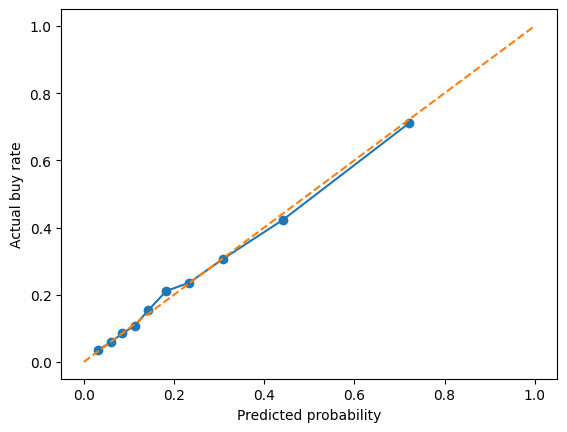

In [ ]:
#points on the dashed line mean they are trustworthy
plt.plot(predicted_rate, actual_rate, marker="o")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("Predicted probability")
plt.ylabel("Actual buy rate")
plt.show()

### 10. Ship it

Score every customer × category, export the CSV.

In [285]:
category_model.eval()

all_customer_features = feature_scaler.transform(training_table[feature_columns])
all_customer_inputs = torch.tensor(all_customer_features, dtype=torch.float32)

with torch.no_grad():
    buy_probabilities = torch.sigmoid(category_model(all_customer_inputs)).numpy()

all_scores = pd.DataFrame(
    buy_probabilities,
    index=training_table["CustomerID"],
    columns=[column.removeprefix("label_") for column in label_columns],
)

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

###### Save per category

In [292]:
typical_spend = history.groupby(["CustomerID", "Category"])["TotalPrice"].sum().groupby("Category").median()

In [293]:
long_scores = all_scores.rename_axis("Category", axis=1).stack().rename("Buy probability").reset_index()

In [294]:
long_scores["Expected spend (£)"] = (long_scores["Buy probability"] * long_scores["Category"].map(typical_spend)).round(2)

In [295]:
long_scores.to_csv("/content/drive/MyDrive/customer_per_category_scores.csv", index=False)

###### Save per customer

In [291]:
all_scores.round(4).to_csv("/content/drive/MyDrive/customer_category_scores.csv")

##### Findings
**Categories:** We built 27 product categories from ~3,400 product descriptions (sentence embeddings + KMeans with k = 23, then keyword rules to split mixed clusters).

**Results on held-out test customers (20%):**

| Model | Mean AUC | Recall@5 |
|---|---|---|
| Purchase frequency (baseline) | 0.72 | 0.70 |
| LightGBM | 0.74 | 0.73 |
| Neural net (256/128 layers, dropout 0.3) | **0.75** | **0.747** |

**The neural net is the best model, by a small margin.** It wins or ties in 20 of 27 categories. Its biggest gains are in the hardest ones: Jewellery & Accessories (+0.058 AUC) and Glassware & Jars (+0.052). Where LightGBM wins, the gap is under 0.012.

**Past purchases carry most of the signal.** The simple "buy what you bought before" baseline is within 0.03 AUC of the best model.

**Probabilities are well calibrated.** The calibration curve sits on the diagonal, so buy probabilities and expected spend can be used as they are.

##### Caveats
**Holiday test window.** Labels cover Sep–Dec 2011, so Christmas is the top category (43% of customers buy it). Results may not hold for other quarters.

**Data scope.** One year of data from one UK online retailer with many wholesale buyers. Transactions without a CustomerID (~25% of rows) were dropped.

**Scoring limits.** Only customers with purchase history can be scored, so new customers get no predictions.

## Extension: combining with the team's repeat-purchaser model

### What we're doing

The team's model predicts who comes back; mine predicts what they'll buy. To combine them, the category model is retrained on returning customers only, so its scores mean "which categories, given they come back." Then:

$$P(\text{buys category}) = P(\text{returns}) \times P(\text{category} \mid \text{returns})$$

The win isn't accuracy, since the standalone model already bakes in returning. It's having a separate return score that powers the marketing playbook below.

### What the final product looks like

The same scored table and two views, plus a return probability column. Every customer also lands in one playbook segment:

| | Clear category preference | No clear preference |
| --- | --- | --- |
| **Likely to return** | Targeted promo for their top category | New arrivals or general loyalty offer |
| **Unlikely to return** | Win-back using the category they love | Don't spend money here |

The bottom-left box is the gold: customers drifting away, but we know exactly what might pull them back.

### Zero to hero

1. **Align with the team.** Same cutoff date and same test customers. Otherwise the combined scores are quietly inflated.
2. **Retrain on returners.** Same pipeline as the standalone model, with one filter: only customers who bought again after the cutoff.
3. **Pull the team's scores.** Get their return probability for every customer.
4. **Calibrate both.** Multiplying two miscalibrated probabilities stacks the error.
5. **Combine.** Multiply the two scores, then multiply by typical category spend to get expected spend.
6. **Segment.** Place each customer in the playbook using their return score and how concentrated their category scores are.
7. **Ship it.** Add the return probability and segment to the CSV and both demo views.

In [ ]:
# TODO: confirm cutoff date + test customers match the team's
# TODO: retrain category model on returners only
# TODO: load team's return probabilities
# TODO: calibrate both, combine, compute expected spend
# TODO: assign playbook segments, add to CSV + demo